In [1]:
%pip install torch matplotlib pandas numpy scikit-learn

   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.8/126.7 MB 5.4 MB/s eta 0:00:24
    --------------------------------------- 1.8/126.7 MB 6.1 MB/s eta 0:00:21
   - -------------------------------------- 3.9/126.7 MB 7.2 MB/s eta 0:00:18
   - -------------------------------------- 4.5/126.7 MB 6.6 MB/s eta 0:00:19
   - -------------------------------------- 5.8/126.7 MB 5.9 MB/s eta 0:00:21
   --- ------------------------------------ 9.7/126.7 MB 8.4 MB/s eta 0:00:14
   ---- ----------------------------------- 13.9/126.7 MB 10.1 MB/s eta 0:00:12
   ----- ---------------------------------- 17.8/126.7 MB 11.0 MB/s eta 0:00:10
   ------ --------------------------------- 20.7/126.7 MB 11.4 MB/s eta 0:00:10
   ------- -------------------------------- 23.3/126.7 MB 11.5 MB/s eta 0:00:10
   -------- ------------------------------- 25.4/126.7 MB 11.2 MB/s eta 0:00:10
   -------- ------------------------------- 27.8/126.7 MB 11.


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("PyTorch version:", torch.__version__)

PyTorch version: 2.15.0+cpu


In [3]:
X, y = make_moons(
    n_samples=1000,
    noise=0.2,
    random_state=42
)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1000, 2)
Target shape: (1000,)


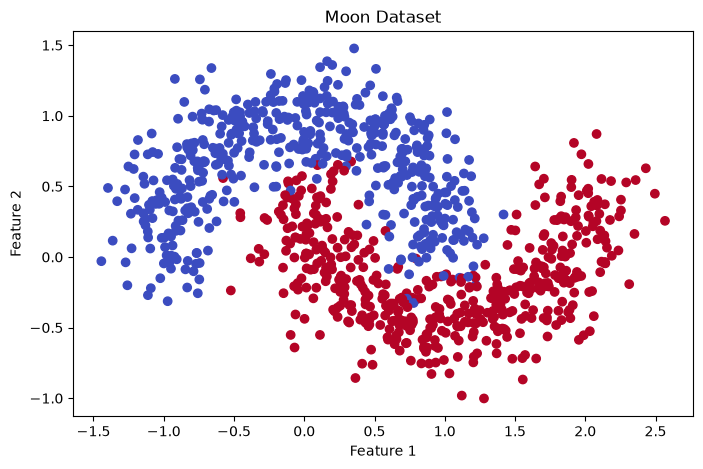

In [4]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Moon Dataset")
plt.show()

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 800
Testing samples: 200


In [6]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [7]:
X_train_tensor = torch.tensor(
    X_train,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.long
)

In [8]:
print("X_train_tensor:", X_train_tensor.shape)
print("X_test_tensor:", X_test_tensor.shape)

print("y_train_tensor:", y_train_tensor.shape)
print("y_test_tensor:", y_test_tensor.shape)

print("Tensor type:", X_train_tensor.dtype)

X_train_tensor: torch.Size([800, 2])
X_test_tensor: torch.Size([200, 2])
y_train_tensor: torch.Size([800])
y_test_tensor: torch.Size([200])
Tensor type: torch.float32


In [9]:
class NeuralNetwork(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),

            nn.Linear(16, 8),
            nn.ReLU(),

            nn.Linear(8, 2)
        )

    def forward(self, x):
        return self.network(x)

In [10]:
model = NeuralNetwork()

print(model)

NeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=2, bias=True)
  )
)


In [11]:
sample_input = X_train_tensor[:5]

output = model(sample_input)

print("Input:")
print(sample_input)

print("\nOutput:")
print(output)

print("\nOutput shape:")
print(output.shape)

Input:
tensor([[-0.3118, -0.8868],
        [-0.0216,  0.9101],
        [ 1.8838,  0.0320],
        [-1.4425, -0.6578],
        [ 1.6197, -0.6673]])

Output:
tensor([[ 0.2219, -0.1321],
        [ 0.0722,  0.1774],
        [ 0.1675,  0.0261],
        [ 0.2794, -0.1675],
        [ 0.2512, -0.0820]], grad_fn=<AddmmBackward0>)

Output shape:
torch.Size([5, 2])


In [12]:
criterion = nn.CrossEntropyLoss()

In [13]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [14]:
from sklearn.model_selection import train_test_split

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_tensor,
    y_train_tensor,
    test_size=0.2,
    random_state=42,
    stratify=y_train_tensor
)

print("Training data:", X_train_final.shape)
print("Validation data:", X_val.shape)

Training data: torch.Size([640, 2])
Validation data: torch.Size([160, 2])


In [15]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(
    X_train_final,
    y_train_final
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

In [1]:
num_epochs = 100

train_losses = []
val_losses = []

for epoch in range(num_epochs):

    # Training mode
    model.train()

    total_train_loss = 0

    for batch_X, batch_y in train_loader:

        # Forward pass
        outputs = model(batch_X)

        # Calculate loss
        loss = criterion(outputs, batch_y)

        # Clear previous gradients
        optimizer.zero_grad()

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        total_train_loss += loss.item() * len(batch_X)

    average_train_loss = total_train_loss / len(train_dataset)

    # Validation mode
    model.eval()

    with torch.no_grad():

        val_outputs = model(X_val)

        val_loss = criterion(val_outputs, y_val)

        average_val_loss = val_loss.item()

    train_losses.append(average_train_loss)
    val_losses.append(average_val_loss)

    # Print results every 10 epochs
    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch [{epoch + 1}/{num_epochs}], "
            f"Train Loss: {average_train_loss:.4f}, "
            f"Validation Loss: {average_val_loss:.4f}"
        )

NameError: name 'model' is not defined

In [2]:
class NeuralNetwork(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),

            nn.Linear(16, 8),
            nn.ReLU(),

            nn.Linear(8, 2)
        )

    def forward(self, x):
        return self.network(x)

NameError: name 'nn' is not defined

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from torch.utils.data import TensorDataset, DataLoader

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
%pip install torch matplotlib pandas numpy scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
X, y = make_moons(
    n_samples=1000,
    noise=0.2,
    random_state=42
)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1000, 2)
Target shape: (1000,)


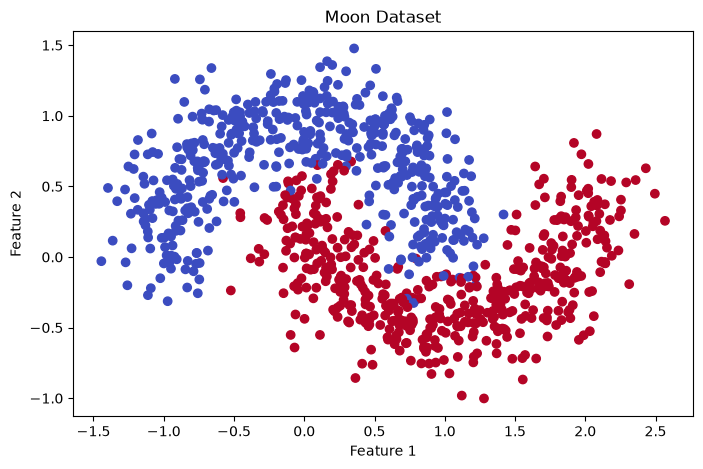

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Moon Dataset")

plt.show()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 800
Testing samples: 200


In [8]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Features scaled successfully!")

Features scaled successfully!


In [9]:
X_train_tensor = torch.tensor(
    X_train,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.long
)

print("Training features:", X_train_tensor.shape)
print("Testing features:", X_test_tensor.shape)
print("Training targets:", y_train_tensor.shape)
print("Testing targets:", y_test_tensor.shape)

Training features: torch.Size([800, 2])
Testing features: torch.Size([200, 2])
Training targets: torch.Size([800])
Testing targets: torch.Size([200])


In [10]:
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_tensor,
    y_train_tensor,
    test_size=0.2,
    random_state=42,
    stratify=y_train_tensor
)

print("Training data:", X_train_final.shape)
print("Validation data:", X_val.shape)

Training data: torch.Size([640, 2])
Validation data: torch.Size([160, 2])


In [11]:
train_dataset = TensorDataset(
    X_train_final,
    y_train_final
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

print("Number of batches:", len(train_loader))

Number of batches: 20


In [12]:
class NeuralNetwork(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),

            nn.Linear(16, 8),
            nn.ReLU(),

            nn.Linear(8, 2)
        )

    def forward(self, x):
        return self.network(x)

In [13]:
model = NeuralNetwork()

print(model)

NeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=2, bias=True)
  )
)


In [14]:
sample_input = X_train_tensor[:5]

output = model(sample_input)

print("Input:")
print(sample_input)

print("\nOutput:")
print(output)

print("\nOutput shape:")
print(output.shape)

Input:
tensor([[-0.3118, -0.8868],
        [-0.0216,  0.9101],
        [ 1.8838,  0.0320],
        [-1.4425, -0.6578],
        [ 1.6197, -0.6673]])

Output:
tensor([[-0.0872, -0.1018],
        [-0.1662, -0.1358],
        [-0.2207, -0.1883],
        [-0.0172, -0.0201],
        [-0.2512, -0.1931]], grad_fn=<AddmmBackward0>)

Output shape:
torch.Size([5, 2])


In [15]:
criterion = nn.CrossEntropyLoss()

print("Loss function created!")

Loss function created!


In [16]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Optimizer created!")

Optimizer created!


In [17]:
num_epochs = 100

train_losses = []
val_losses = []

for epoch in range(num_epochs):

    # Training mode
    model.train()

    total_train_loss = 0

    for batch_X, batch_y in train_loader:

        # Forward pass
        outputs = model(batch_X)

        # Calculate loss
        loss = criterion(outputs, batch_y)

        # Clear previous gradients
        optimizer.zero_grad()

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        total_train_loss += loss.item() * len(batch_X)

    average_train_loss = total_train_loss / len(train_dataset)

    # Validation mode
    model.eval()

    with torch.no_grad():

        val_outputs = model(X_val)

        val_loss = criterion(val_outputs, y_val)

        average_val_loss = val_loss.item()

    train_losses.append(average_train_loss)
    val_losses.append(average_val_loss)

    # Print results every 10 epochs
    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch [{epoch + 1}/{num_epochs}], "
            f"Train Loss: {average_train_loss:.4f}, "
            f"Validation Loss: {average_val_loss:.4f}"
        )

Epoch [10/100], Train Loss: 0.3200, Validation Loss: 0.3679
Epoch [20/100], Train Loss: 0.2454, Validation Loss: 0.3131
Epoch [30/100], Train Loss: 0.1795, Validation Loss: 0.2356
Epoch [40/100], Train Loss: 0.1292, Validation Loss: 0.1740
Epoch [50/100], Train Loss: 0.1030, Validation Loss: 0.1408
Epoch [60/100], Train Loss: 0.0887, Validation Loss: 0.1265
Epoch [70/100], Train Loss: 0.0809, Validation Loss: 0.1140
Epoch [80/100], Train Loss: 0.0763, Validation Loss: 0.1117
Epoch [90/100], Train Loss: 0.0742, Validation Loss: 0.1076
Epoch [100/100], Train Loss: 0.0710, Validation Loss: 0.1061


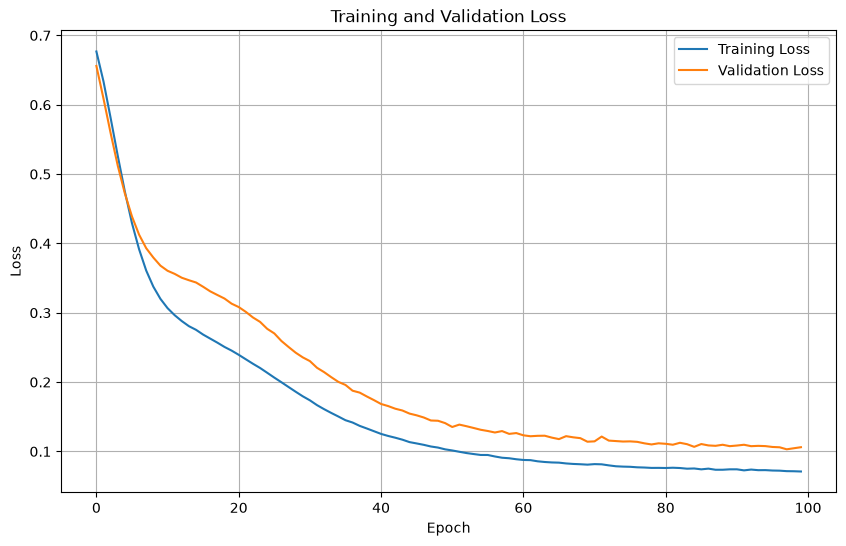

In [18]:
plt.figure(figsize=(10, 6))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

In [19]:
model.eval()

with torch.no_grad():

    train_outputs = model(X_train_final)

    train_predictions = torch.argmax(
        train_outputs,
        dim=1
    )

    train_accuracy = (
        train_predictions == y_train_final
    ).float().mean()

print("Training Accuracy:", train_accuracy.item() * 100, "%")

Training Accuracy: 97.65625 %


In [20]:
model.eval()

with torch.no_grad():

    val_outputs = model(X_val)

    val_predictions = torch.argmax(
        val_outputs,
        dim=1
    )

    val_accuracy = (
        val_predictions == y_val
    ).float().mean()

print("Validation Accuracy:", val_accuracy.item() * 100, "%")

Validation Accuracy: 94.37500238418579 %


In [21]:
model.eval()

with torch.no_grad():

    test_outputs = model(X_test_tensor)

    test_predictions = torch.argmax(
        test_outputs,
        dim=1
    )

    test_accuracy = (
        test_predictions == y_test_tensor
    ).float().mean()

print("Test Accuracy:", test_accuracy.item() * 100, "%")

Test Accuracy: 99.00000095367432 %


In [22]:
comparison = pd.DataFrame({
    "Actual": y_test_tensor.numpy(),
    "Predicted": test_predictions.numpy()
})

print(comparison.head(20))

    Actual  Predicted
0        1          1
1        0          0
2        0          0
3        0          0
4        1          1
5        1          1
6        1          1
7        1          1
8        0          0
9        0          0
10       1          1
11       1          1
12       1          1
13       0          0
14       0          0
15       0          0
16       1          1
17       0          0
18       1          1
19       0          0


In [23]:
from sklearn.metrics import classification_report, confusion_matrix

print("Classification Report:")

print(
    classification_report(
        y_test_tensor.numpy(),
        test_predictions.numpy()
    )
)

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       100
           1       0.98      1.00      0.99       100

    accuracy                           0.99       200
   macro avg       0.99      0.99      0.99       200
weighted avg       0.99      0.99      0.99       200



In [24]:
cm = confusion_matrix(
    y_test_tensor.numpy(),
    test_predictions.numpy()
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 98   2]
 [  0 100]]


In [25]:
class NeuralNetworkDropout(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(8, 2)
        )

    def forward(self, x):
        return self.network(x)

In [26]:
dropout_model = NeuralNetworkDropout()

dropout_optimizer = torch.optim.Adam(
    dropout_model.parameters(),
    lr=0.001
)

criterion = nn.CrossEntropyLoss()

In [27]:
num_epochs = 100

dropout_train_losses = []
dropout_val_losses = []

for epoch in range(num_epochs):

    dropout_model.train()

    total_train_loss = 0

    for batch_X, batch_y in train_loader:

        outputs = dropout_model(batch_X)

        loss = criterion(outputs, batch_y)

        dropout_optimizer.zero_grad()

        loss.backward()

        dropout_optimizer.step()

        total_train_loss += loss.item() * len(batch_X)

    average_train_loss = total_train_loss / len(train_dataset)

    dropout_model.eval()

    with torch.no_grad():

        val_outputs = dropout_model(X_val)

        val_loss = criterion(val_outputs, y_val)

        average_val_loss = val_loss.item()

    dropout_train_losses.append(average_train_loss)
    dropout_val_losses.append(average_val_loss)

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch [{epoch + 1}/{num_epochs}], "
            f"Train Loss: {average_train_loss:.4f}, "
            f"Validation Loss: {average_val_loss:.4f}"
        )

Epoch [10/100], Train Loss: 0.3623, Validation Loss: 0.3595
Epoch [20/100], Train Loss: 0.3226, Validation Loss: 0.3335
Epoch [30/100], Train Loss: 0.2847, Validation Loss: 0.3112
Epoch [40/100], Train Loss: 0.2561, Validation Loss: 0.2854
Epoch [50/100], Train Loss: 0.2427, Validation Loss: 0.2591
Epoch [60/100], Train Loss: 0.2209, Validation Loss: 0.2352
Epoch [70/100], Train Loss: 0.2099, Validation Loss: 0.2267
Epoch [80/100], Train Loss: 0.1947, Validation Loss: 0.2096
Epoch [90/100], Train Loss: 0.1711, Validation Loss: 0.1960
Epoch [100/100], Train Loss: 0.1786, Validation Loss: 0.1855


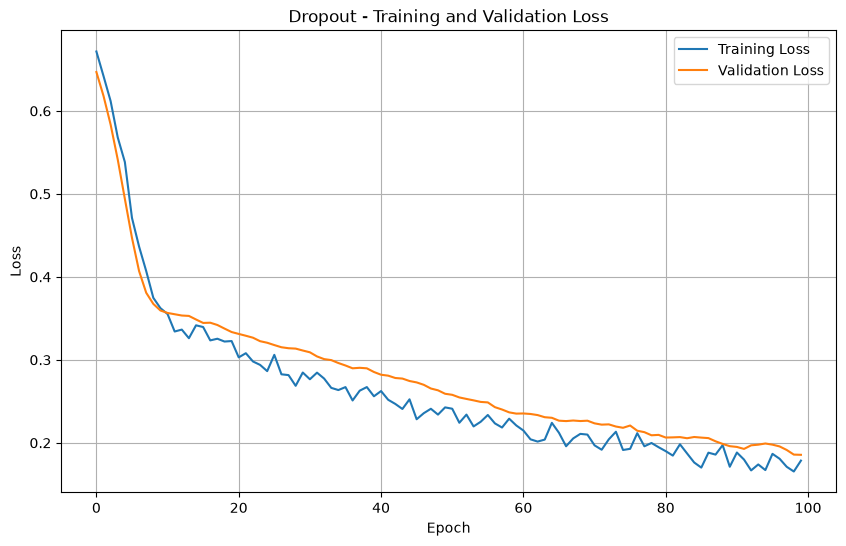

In [28]:
plt.figure(figsize=(10, 6))

plt.plot(
    dropout_train_losses,
    label="Training Loss"
)

plt.plot(
    dropout_val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Dropout - Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

In [29]:
dropout_model.eval()

with torch.no_grad():

    dropout_test_outputs = dropout_model(X_test_tensor)

    dropout_test_predictions = torch.argmax(
        dropout_test_outputs,
        dim=1
    )

    dropout_test_accuracy = (
        dropout_test_predictions == y_test_tensor
    ).float().mean()

print(
    "Dropout Test Accuracy:",
    dropout_test_accuracy.item() * 100,
    "%"
)

Dropout Test Accuracy: 97.50000238418579 %


In [30]:
weight_decay_model = NeuralNetwork()

weight_decay_optimizer = torch.optim.Adam(
    weight_decay_model.parameters(),
    lr=0.001,
    weight_decay=0.01
)

criterion = nn.CrossEntropyLoss()

In [31]:
num_epochs = 100

weight_decay_train_losses = []
weight_decay_val_losses = []

for epoch in range(num_epochs):

    weight_decay_model.train()

    total_train_loss = 0

    for batch_X, batch_y in train_loader:

        outputs = weight_decay_model(batch_X)

        loss = criterion(outputs, batch_y)

        weight_decay_optimizer.zero_grad()

        loss.backward()

        weight_decay_optimizer.step()

        total_train_loss += loss.item() * len(batch_X)

    average_train_loss = total_train_loss / len(train_dataset)

    weight_decay_model.eval()

    with torch.no_grad():

        val_outputs = weight_decay_model(X_val)

        val_loss = criterion(val_outputs, y_val)

        average_val_loss = val_loss.item()

    weight_decay_train_losses.append(average_train_loss)
    weight_decay_val_losses.append(average_val_loss)

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch [{epoch + 1}/{num_epochs}], "
            f"Train Loss: {average_train_loss:.4f}, "
            f"Validation Loss: {average_val_loss:.4f}"
        )

Epoch [10/100], Train Loss: 0.3083, Validation Loss: 0.3553
Epoch [20/100], Train Loss: 0.2702, Validation Loss: 0.3303
Epoch [30/100], Train Loss: 0.2439, Validation Loss: 0.2974
Epoch [40/100], Train Loss: 0.2132, Validation Loss: 0.2639
Epoch [50/100], Train Loss: 0.1826, Validation Loss: 0.2291
Epoch [60/100], Train Loss: 0.1585, Validation Loss: 0.1994
Epoch [70/100], Train Loss: 0.1417, Validation Loss: 0.1778
Epoch [80/100], Train Loss: 0.1296, Validation Loss: 0.1666
Epoch [90/100], Train Loss: 0.1223, Validation Loss: 0.1620
Epoch [100/100], Train Loss: 0.1175, Validation Loss: 0.1544


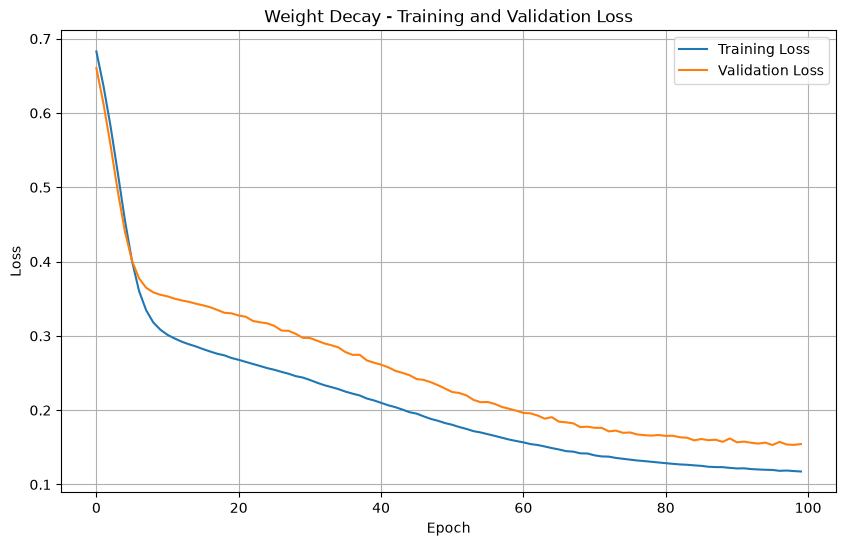

In [32]:
plt.figure(figsize=(10, 6))

plt.plot(
    weight_decay_train_losses,
    label="Training Loss"
)

plt.plot(
    weight_decay_val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Weight Decay - Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

In [33]:
weight_decay_model.eval()

with torch.no_grad():

    weight_decay_test_outputs = weight_decay_model(X_test_tensor)

    weight_decay_test_predictions = torch.argmax(
        weight_decay_test_outputs,
        dim=1
    )

    weight_decay_test_accuracy = (
        weight_decay_test_predictions == y_test_tensor
    ).float().mean()

print(
    "Weight Decay Test Accuracy:",
    weight_decay_test_accuracy.item() * 100,
    "%"
)

Weight Decay Test Accuracy: 97.50000238418579 %


In [34]:
results = pd.DataFrame({
    "Model": [
        "Original Neural Network",
        "Neural Network with Dropout",
        "Neural Network with Weight Decay"
    ],

    "Test Accuracy": [
        test_accuracy.item() * 100,
        dropout_test_accuracy.item() * 100,
        weight_decay_test_accuracy.item() * 100
    ],

    "Final Training Loss": [
        train_losses[-1],
        dropout_train_losses[-1],
        weight_decay_train_losses[-1]
    ],

    "Final Validation Loss": [
        val_losses[-1],
        dropout_val_losses[-1],
        weight_decay_val_losses[-1]
    ]
})

results = results.round(4)

print(results)

                              Model  Test Accuracy  Final Training Loss  \
0           Original Neural Network           99.0               0.0710   
1       Neural Network with Dropout           97.5               0.1786   
2  Neural Network with Weight Decay           97.5               0.1175   

   Final Validation Loss  
0                 0.1061  
1                 0.1855  
2                 0.1544  


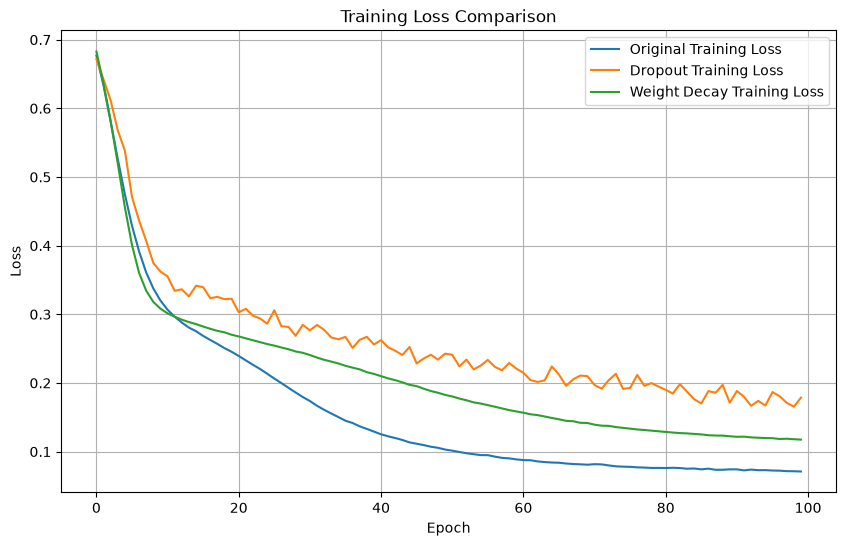

In [35]:
plt.figure(figsize=(10, 6))

plt.plot(
    train_losses,
    label="Original Training Loss"
)

plt.plot(
    dropout_train_losses,
    label="Dropout Training Loss"
)

plt.plot(
    weight_decay_train_losses,
    label="Weight Decay Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss Comparison")

plt.legend()
plt.grid(True)

plt.show()

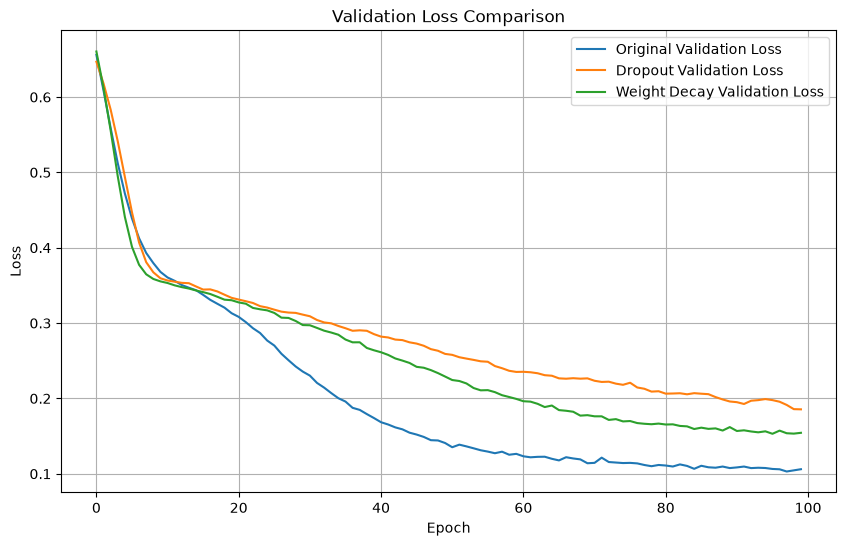

In [36]:
plt.figure(figsize=(10, 6))

plt.plot(
    val_losses,
    label="Original Validation Loss"
)

plt.plot(
    dropout_val_losses,
    label="Dropout Validation Loss"
)

plt.plot(
    weight_decay_val_losses,
    label="Weight Decay Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Validation Loss Comparison")

plt.legend()
plt.grid(True)

plt.show()